# MyFinSight 분석 결과 한눈에 보기

`output/13_results.json` 하나만 읽어서, 파이프라인이 **무엇을 받아(요청) → 어떻게 이해하고(의도) → 어떤 종목을 골라(선정) → 어떻게 나누고(구성) → 과거에 적용하면 어땠고(백테스트) → 기준을 통과했는지(검증)** 를 순서대로 보여줍니다.
각 절의 표와 그래프는 모두 같은 결과 파일의 숫자입니다.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.family"] = "AppleGothic"      # macOS 한글 폰트 (다른 OS: 'Malgun Gothic' / 'NanumGothic')
mpl.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)

import os
RESULTS = Path(os.environ.get("MYFINSIGHT_RESULTS", "../output/13_results.json"))   # 기본: notebooks/ 기준 상대 경로
R = json.loads(RESULTS.read_text(encoding="utf-8"))
pct = lambda x: "–" if x is None else f"{x*100:+.2f}%"
pct1 = lambda x: "–" if x is None else f"{x*100:.1f}%"
usd = lambda x: "–" if x is None else f"{x:,.2f} USD"
krw = lambda x: "–" if x is None else f"{x:,.0f}원"
print("request_id:", R["request_id"], "| generated:", R["generated_at"], "| pipeline:", R["pipeline_version"])

request_id: req_2026-10-09_001 | generated: 2026-10-09T22:47:51 | pipeline: mockup-2026.10


## 1. 요청 — 사용자가 입력한 것

In [2]:
q, d, c, h, r = R["request"], R["request"]["derived"], R["request"]["capital"], R["request"]["horizon"], R["request"]["risk"]
rows = [("투자금", f"{c['initial_amount']:,.0f}원 → {usd(d['initial_amount_usd'])}  (환율 {R['money_krw']['direction']}, {d['fx_date']})"),
        ("월 적립", f"{c['monthly_contribution']:,.0f}원 (매월 {c['contribution_day']}일) → {usd(d['monthly_contribution_usd'])}"),
        ("투자기간", f"{h['target_years']}년, 시작 희망일 {h['start_date']}"),
        ("투자성향", f"{r['risk_tolerance']} · 손실 감내 수준 {r['max_drawdown_tolerance']:.0%} · 손실 시 {r['loss_reaction']}"),
        ("목표 수익률 / 비교지수", f"연 {r['target_annual_return']:.0%} / {r['benchmark']}"),
        ("전략 템플릿 / 기준 비중", f"{q['strategy_preference']['template']} / {q['strategy_preference']['baseline_weighting']}"),
        ("투자 아이디어", q["natural_language"]["idea"])]
pd.DataFrame(rows, columns=["항목", "내용"]).set_index("항목")

,내용
항목,
투자금,"10,000,000원 → 6,651.90 USD (환율 1 USD = 1,503.33 KRW, 2026-04-01)"
월 적립,"500,000원 (매월 25일) → 332.59 USD"
투자기간,"3.0년, 시작 희망일 2026-04-01"
투자성향,moderate · 손실 감내 수준 25% · 손실 시 hold
목표 수익률 / 비교지수,연 12% / SPY
전략 템플릿 / 기준 비중,momentum / equal_weight
투자 아이디어,AI 반도체와 클라우드 인프라 관련 기업 중 최근 1년간 주가 흐름이 강한 종목 위주로 3년 정도 들고 가고 싶어요. 변동성은 어느 정도...


## 2. 의도 해석 — 분석 모델이 아이디어를 어떻게 이해했나

In [3]:
I = R["intent"]
print(I["interpretation"]["summary_ko"]); print()
themes = pd.DataFrame([{"테마": t["label_ko"], "설명": t["description_ko"], "GICS 코드": ", ".join(t["gics_codes"]), "키워드": ", ".join(t["keywords"][:6])} for t in I["interpretation"]["themes"]])
display(themes.set_index("테마"))
cons = q["constraints"]
display(pd.DataFrame([("종목 수", f"목표 {cons['num_holdings']['target']} (허용 {cons['num_holdings']['min']}~{cons['num_holdings']['max']})"), ("종목당 상한", f"{cons['max_weight_per_stock']:.0%}"), ("섹터당 상한", f"{cons['max_weight_per_sector']:.0%}"),
                      ("리밸런싱", d["rebalance_rule"]["description_ko"]), ("제외 테마", ", ".join(cons["exclude_themes"]) or "없음"),
                      ("변동성 선호 / 허용 MDD", f"{I['risk_params']['volatility_preference']} / {I['risk_params']['effective_max_drawdown']:.0%}"), ("해석 메모", I["risk_params"]["notes_ko"])], columns=["항목", "값"]).set_index("항목"))
if I["interpretation"]["conflicts"]:
    display(pd.DataFrame(I["interpretation"]["conflicts"]).rename(columns={"field": "항목", "issue_ko": "확인한 점", "resolution_ko": "처리"}))

AI 반도체와 클라우드 인프라 기업 가운데 최근 1년 주가 모멘텀이 강한 종목을 15개 골라 3년간 분산 보유하려는 요청.



,설명,GICS 코드,키워드
테마,,,
AI 반도체,"AI 학습·추론용 GPU/가속기, 고대역폭 메모리, AI 칩 설계 IP, 첨단 반도체 장비·EDA 등 AI 연산 수요의 직접 수혜 기업",453010,"gpu, ai accelerator, semiconductor, chip, hbm, memory"
클라우드 인프라,"하이퍼스케일 클라우드 서비스, AI 전용 클라우드, 데이터센터 서버·네트워크 장비, 데이터센터 전력·냉각, 데이터센터 리츠 등 클라우드 ...","45102030, 451020, 45103020, 45202030, 45201020, 20104010, 60108050","cloud, data center, hyperscale, server, networking, colocation"


,값
항목,
종목 수,목표 15 (허용 10~20)
종목당 상한,15%
섹터당 상한,40%
리밸런싱,1×분기마다 리밸런싱
제외 테마,"tobacco, gambling"
변동성 선호 / 허용 MDD,medium / 25%
해석 메모,"loss_reaction=hold, experience=beginner 이므로 보정 없이 0.25 유지. 자연어에서 변동성 감수 의사를 ..."


,항목,확인한 점,처리
0,horizon.target_years vs strategy_preference.template,3년 장기 보유 의도와 12개월 모멘텀 스크린은 시간 척도가 다름. 모멘텀 효과는 리밸런싱으로 유지됨,"명시 입력(momentum, 분기 리밸런싱)을 유지하고 리포트에 리밸런싱 의존성을 명시"


## 3. 종목 선정 — 깔때기와 선정 표

유니버스 → 테마 관련 후보(GICS·키워드) → 테마 해당 판정(분석 모델) → 선정 지표 순위 → 섹터 상한 → 최종. 백테스트는 시작일 당시 정보로 같은 규칙을 다시 적용하므로 목록이 다를 수 있습니다.

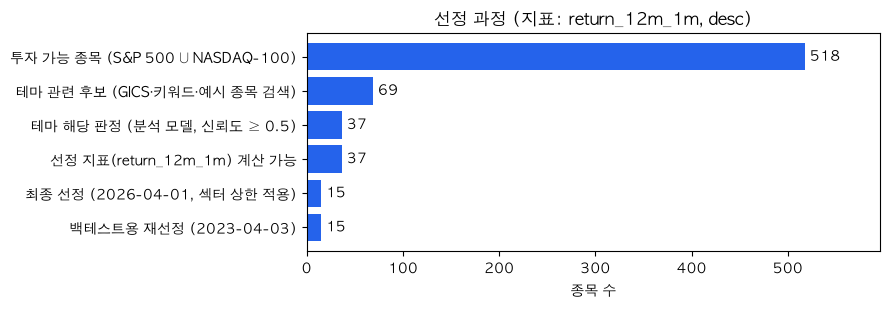

,회사,섹터,테마,신뢰도,순위(2023-04-03),지표(백테스트),순위(2026-04-01),지표(2026),테마 판정 사유
티커,,,,,,,,,
ETN,Eaton Corporation,Industrials,cloud_infrastructure,0.50,1.0,+19.51%,10.0,+32.00%,데이터센터 전력장비 수요 급증
CDNS,Cadence Design Systems,Information Technology,ai_semiconductor,0.65,2.0,+19.48%,NaN,+nan%,AI 칩 설계용 EDA 툴·IP
SNPS,Synopsys,Information Technology,ai_semiconductor,0.65,3.0,+10.27%,NaN,+nan%,AI 칩 설계용 EDA 툴·IP
ORCL,Oracle Corporation,Information Technology,cloud_infrastructure,0.85,4.0,+9.76%,NaN,+nan%,"OCI 클라우드, AI 데이터센터 대형 수주"
KLAC,KLA Corporation,Information Technology,ai_semiconductor,0.70,5.0,+5.64%,NaN,+nan%,반도체 공정 검사·계측 장비
MPWR,Monolithic Power Systems,Information Technology,"ai_semiconductor, cloud_infrastructure",0.50,6.0,+4.82%,NaN,+nan%,AI 서버 GPU 전력관리 반도체
AVGO,Broadcom,Information Technology,"ai_semiconductor, cloud_infrastructure",0.90,7.0,+3.02%,NaN,+nan%,하이퍼스케일러 맞춤형 AI ASIC 과 데이터센터 네트워크 칩
EQIX,Equinix,Real Estate,cloud_infrastructure,0.90,8.0,-3.54%,12.0,+21.98%,글로벌 데이터센터 코로케이션 리츠
DLR,Digital Realty,Real Estate,cloud_infrastructure,0.90,9.0,-22.90%,11.0,+27.08%,하이퍼스케일 데이터센터 리츠


백테스트 재선정에서 추가: ['ANET', 'ASML', 'AVGO', 'CDNS', 'HPE', 'KLAC', 'LRCX', 'MPWR', 'ORCL', 'SNPS'] | 빠짐: ['BE', 'CIEN', 'LITE', 'MU', 'NBIS', 'SNDK', 'STX', 'TER', 'VRT', 'WDC']


,회사,제외 이유,지표값
티커,,,
LRCX,Lam Research,rank_beyond_n,2.006878
AMAT,Applied Materials,rank_beyond_n,1.442550
KLAC,KLA Corporation,rank_beyond_n,1.136331
ASML,ASML Holding,rank_beyond_n,1.071826
INTC,Intel,rank_beyond_n,0.897842
AVGO,Broadcom,rank_beyond_n,0.885687
MPWR,Monolithic Power Systems,rank_beyond_n,0.862778
AMD,Advanced Micro Devices,rank_beyond_n,0.858575


In [4]:
S = R["selection"]
f = pd.DataFrame(S["funnel"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(f["label_ko"][::-1], f["count"][::-1], color="#2563eb")
for i, v in enumerate(f["count"][::-1]): ax.text(v + 5, i, str(v), va="center")
ax.set_xlabel("종목 수"); ax.set_title(f"선정 과정 (지표: {S['metric']}, {S['direction']})"); ax.set_xlim(0, f["count"].max() * 1.15)
plt.tight_layout(); plt.show()

t = pd.DataFrame(S["table"])
view = t[["ticker", "name", "sector", "themes", "theme_confidence", "rank_backtest", "metric_backtest", "rank_2026", "metric_2026", "theme_reason_ko"]].copy()
view["themes"] = view["themes"].str.join(", "); view["metric_backtest"] = view["metric_backtest"].map(pct); view["metric_2026"] = view["metric_2026"].map(pct)
view.columns = ["티커", "회사", "섹터", "테마", "신뢰도", f"순위({S['backtest_as_of']['as_of']})", "지표(백테스트)", f"순위({S['as_of_2026']['as_of']})", "지표(2026)", "테마 판정 사유"]
display(view.set_index("티커"))
diff = S["backtest_as_of"]["diff_vs_original"]
print("백테스트 재선정에서 추가:", diff["added"], "| 빠짐:", diff["removed"])
display(pd.DataFrame(S["as_of_2026"]["rejected_examples"]).rename(columns={"ticker": "티커", "name": "회사", "reason": "제외 이유", "metric_value": "지표값"}).set_index("티커"))

## 4. 포트폴리오 구성 — 기준 비중, 규칙 4가지, 시나리오 5개

기준은 1/N 동일비중이고, 종목·섹터 상한으로 재배분합니다. Black-Litterman 타겟은 기준 비중에 시나리오 뷰를 종목당 최대 `max_tilt` 만큼만 반영한 것입니다.

,섹터,1/N,최종 비중
ETN,Industrials,6.7%,12.0%
CDNS,Information Technology,6.7%,4.0%
SNPS,Information Technology,6.7%,4.0%
ORCL,Information Technology,6.7%,4.0%
KLAC,Information Technology,6.7%,4.0%
MPWR,Information Technology,6.7%,4.0%
AVGO,Information Technology,6.7%,4.0%
EQIX,Real Estate,6.7%,12.0%
DLR,Real Estate,6.7%,12.0%
GOOGL,Communication Services,6.7%,12.0%


적용된 제약: ['sector_cap:Information Technology'] | 섹터 비중: {'Industrials': 0.12, 'Information Technology': 0.4, 'Real Estate': 0.24, 'Communication Services': 0.12, 'Consumer Discretionary': 0.12}


,설명,예상 변동성,유효 종목 수,최대 비중
규칙,,,,
동일비중,모든 종목에 같은 비중 1/N,25.3%,11.4,12.0%
시가총액비중,시가총액에 비례한 비중 (지수 방식),25.0%,9.5,15.0%
역변동성비중,변동성이 낮은 종목에 더 큰 비중 (1/σ 정규화),24.5%,11.2,13.4%
최소분산,포트폴리오 분산을 최소화하는 비중 (제약 포함 최적화),21.8%,7.4,15.0%


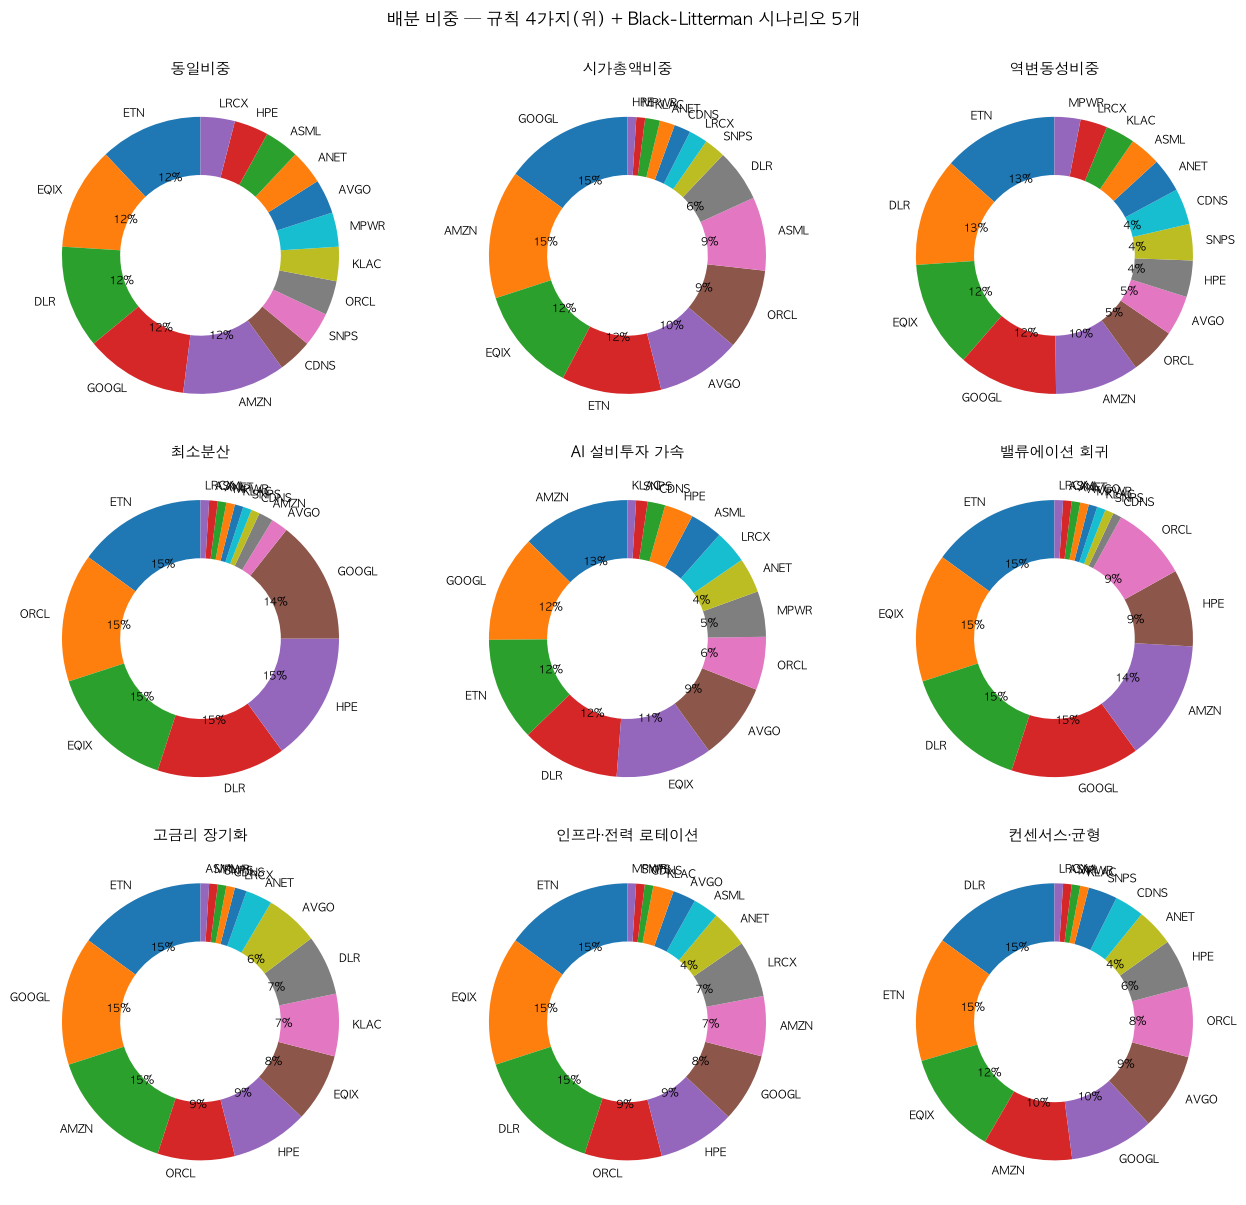

In [5]:
P = R["portfolio"]; base = next(p for p in P["baselines"]["portfolios"] if p["id"] == P["baselines"]["chosen_baseline"])
n = len(base["weights"]); sec = {x["ticker"]: x["sector"] for x in S["table"]}
bt_ = pd.DataFrame({"섹터": {t: sec.get(t, "") for t in base["weights"]}, "1/N": {t: 1/n for t in base["weights"]}, "최종 비중": base["weights"]})
display(bt_.style.format({"1/N": "{:.1%}", "최종 비중": "{:.1%}"}))
print("적용된 제약:", base["constraints_applied"], "| 섹터 비중:", {k: round(v, 3) for k, v in base["sector_weights"].items()})

tmpl = pd.DataFrame([{"규칙": p["name_ko"], "설명": p["rule_ko"], "예상 변동성": p["ex_ante"]["vol"], "유효 종목 수": p["ex_ante"]["effective_n"], "최대 비중": max(p["weights"].values())} for p in P["baselines"]["portfolios"]])
display(tmpl.set_index("규칙").style.format({"예상 변동성": "{:.1%}", "최대 비중": "{:.1%}", "유효 종목 수": "{:.1f}"}))

ports = P["baselines"]["portfolios"] + P["targets"]["portfolios"]
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, p in zip(axes.flat, ports):
    items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
    ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
    ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=11)
plt.suptitle("배분 비중 — 규칙 4가지(위) + Black-Litterman 시나리오 5개", y=1.0); plt.tight_layout(); plt.show()

,관점,뷰,최대 변화,예상 수익,예상 변동성
시나리오,,,,,
AI 설비투자 가속,"생성형 AI 확산으로 하이퍼스케일러의 데이터센터 투자가 예상보다 빠르게 늘어난다고 봅니다. 맞춤형 AI 반도체와 공정 장비, 칩 설계 소프트웨어가 가장 먼저 수혜를 받고, 데이터센터 리츠는 공급 부족으로 임대료가 오르지만 금리 부담이 상쇄합니다.",[절대] AVGO +30%/년 (신뢰 0.50) / [절대] KLAC +22%/년 (신뢰 0.40) / [상대] CDNS+SNPS > ORCL +8%/년 (신뢰 0.40) / [상대] AVGO+KLAC+MPWR > EQIX+DLR +12%/년 (신뢰 0.45),+5.0%,21.4%,25.3%
밸류에이션 회귀,"2022년 급락 뒤 반등한 고PER 소프트웨어·반도체의 밸류에이션이 과도하다고 봅니다. 이익 성장이 확인될 때까지 대형 플랫폼과 리츠처럼 상대적으로 싼 자산이 우위를 점하고, EDA 종목은 기대수익률이 낮아집니다.",[절대] CDNS +5%/년 (신뢰 0.40) / [절대] SNPS +5%/년 (신뢰 0.35) / [상대] GOOGL+AMZN > CDNS+SNPS +10%/년 (신뢰 0.40) / [상대] EQIX+DLR > MPWR +6%/년 (신뢰 0.30),+5.0%,13.6%,23.1%
고금리 장기화,"인플레이션이 더디게 내려와 기준금리가 오래 높게 유지된다고 봅니다. 부채 비중이 큰 데이터센터 리츠가 가장 불리하고, 현금흐름이 탄탄한 소프트웨어·산업재가 상대적으로 유리합니다.",[절대] EQIX +2%/년 (신뢰 0.40) / [절대] DLR +0%/년 (신뢰 0.40) / [상대] ORCL+ETN > EQIX+DLR +10%/년 (신뢰 0.45) / [상대] GOOGL > AMZN +5%/년 (신뢰 0.30),+5.0%,15.6%,24.6%
인프라·전력 로테이션,"AI 데이터센터의 병목이 칩이 아니라 전력·냉각·상면이라고 봅니다. 전력 장비와 데이터센터 리츠로 수혜가 확산되고, 이미 많이 오른 설계 소프트웨어는 상대적으로 뒤처집니다.",[절대] ETN +25%/년 (신뢰 0.50) / [절대] DLR +15%/년 (신뢰 0.40) / [상대] ETN+DLR+EQIX > CDNS+SNPS +8%/년 (신뢰 0.40) / [상대] ORCL > AMZN +6%/년 (신뢰 0.30),+5.0%,19.4%,23.7%
컨센서스·균형,특정 시나리오에 베팅하지 않고 시장 컨센서스에 가까운 완만한 뷰만 반영합니다. 대형 플랫폼의 완만한 회복과 반도체 사이클 바닥 통과를 가정하되 신뢰도를 낮게 두어 베이스라인에서 크게 벗어나지 않습니다.,[절대] GOOGL +15%/년 (신뢰 0.40) / [절대] AMZN +18%/년 (신뢰 0.40) / [상대] AVGO > KLAC+MPWR +5%/년 (신뢰 0.30) / [상대] CDNS+SNPS > EQIX+DLR +5%/년 (신뢰 0.30),+5.0%,15.9%,23.4%


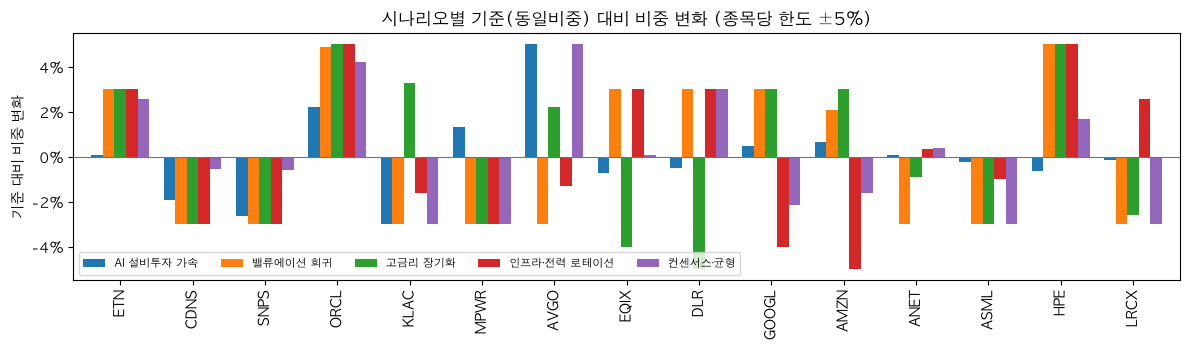

In [6]:
sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                    "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in P["targets"]["portfolios"]])
display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
dl = pd.DataFrame({p["title_ko"]: p["delta_vs_baseline"] for p in P["targets"]["portfolios"]})
ax = dl.plot.bar(figsize=(12, 3.6), width=0.8); ax.axhline(0, color="#64748b", lw=0.8); ax.set_ylabel("기준 대비 비중 변화"); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title(f"시나리오별 기준(동일비중) 대비 비중 변화 (종목당 한도 ±{P['targets']['parameters']['max_tilt_per_stock']:.0%})"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 5. 백테스트 — 같은 기간·같은 적립으로 9개 포트폴리오와 비교지수를 돌린 결과

In [7]:
BT = R["backtest"]; rec = R["validation"].get("recommended"); chosen = rec["id"] if rec else P["targets"]["baseline"]["id"]
label = lambda p: (f"시나리오: {p['title_ko']}" if p.get("title_ko") else p["name_ko"])
E = BT["engine"]; print(f"기간 {BT['period']['start']}~{BT['period']['end']} ({BT['period']['trading_days']}거래일) · 적립 {E['n_contributions']}회 × {E['contribution_usd']:.0f} USD · 거래비용 {E['commission_bps']}bp · 무위험 {E['risk_free_rate']:.0%} · {E['prices']}")
print("중심 포트폴리오:", chosen, "(추천)" if rec else "(추천 없음 → 기준 포트폴리오)")
rows = []
for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]:
    h, m = p["headline"], p["metrics"]
    rows.append({"포트폴리오": label(p), "종류": p["kind"], "누적수익": m["return"]["total_return"], "CAGR": h["cagr"], "변동성": m["risk"]["ann_vol"], "Sharpe": h["sharpe"], "최대낙폭": h["max_drawdown"],
                 "SPY 대비": h["excess_cagr"], "최종 평가금액": h["final_value_usd"], "투입 원금": p["money"]["net_invested_usd"], "XIRR": p["money"]["irr_annual"], "뷰 적중": h["view_hit_ratio"]})
comp = pd.DataFrame(rows).set_index("포트폴리오")
display(comp.style.format({"누적수익": "{:+.1%}", "CAGR": "{:+.1%}", "변동성": "{:.1%}", "Sharpe": "{:.2f}", "최대낙폭": "{:.1%}", "SPY 대비": "{:+.1%}", "최종 평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "XIRR": "{:+.1%}", "뷰 적중": "{:.0%}"}, na_rep="–").background_gradient(subset=["Sharpe"], cmap="Blues"))

기간 2023-04-03~2026-04-01 (752거래일) · 적립 35회 × 383 USD · 거래비용 5bp · 무위험 4% · adj_close (dividends reinvested)
중심 포트폴리오: equal_weight (추천 없음 → 기준 포트폴리오)


,종류,누적수익,CAGR,변동성,Sharpe,최대낙폭,SPY 대비,최종 평가금액,투입 원금,XIRR,뷰 적중
포트폴리오,,,,,,,,,,,
시나리오: AI 설비투자 가속,black_litterman,+151.1%,+36.2%,24.4%,1.32,-29.4%,+17.8%,"39,311","21,065",+33.8%,75%
시나리오: 밸류에이션 회귀,black_litterman,+118.6%,+30.0%,21.6%,1.20,-29.5%,+11.6%,"35,241","21,065",+27.5%,50%
시나리오: 고금리 장기화,black_litterman,+147.5%,+35.5%,24.1%,1.31,-30.5%,+17.1%,"38,746","21,065",+33.0%,50%
시나리오: 인프라·전력 로테이션,black_litterman,+133.5%,+32.9%,23.5%,1.23,-29.9%,+14.5%,"37,454","21,065",+31.0%,50%
시나리오: 컨센서스·균형,black_litterman,+133.1%,+32.8%,23.5%,1.23,-30.3%,+14.4%,"36,654","21,065",+29.7%,50%
동일비중,template,+136.4%,+33.5%,23.8%,1.24,-28.8%,+15.1%,"37,657","21,065",+31.3%,–
시가총액비중,template,+146.8%,+35.4%,24.0%,1.31,-28.1%,+17.0%,"38,723","21,065",+32.9%,–
역변동성비중,template,+133.3%,+32.9%,23.6%,1.22,-29.0%,+14.5%,"37,160","21,065",+30.5%,–
최소분산,template,+115.4%,+29.4%,22.8%,1.11,-31.3%,+11.0%,"35,142","21,065",+27.3%,–


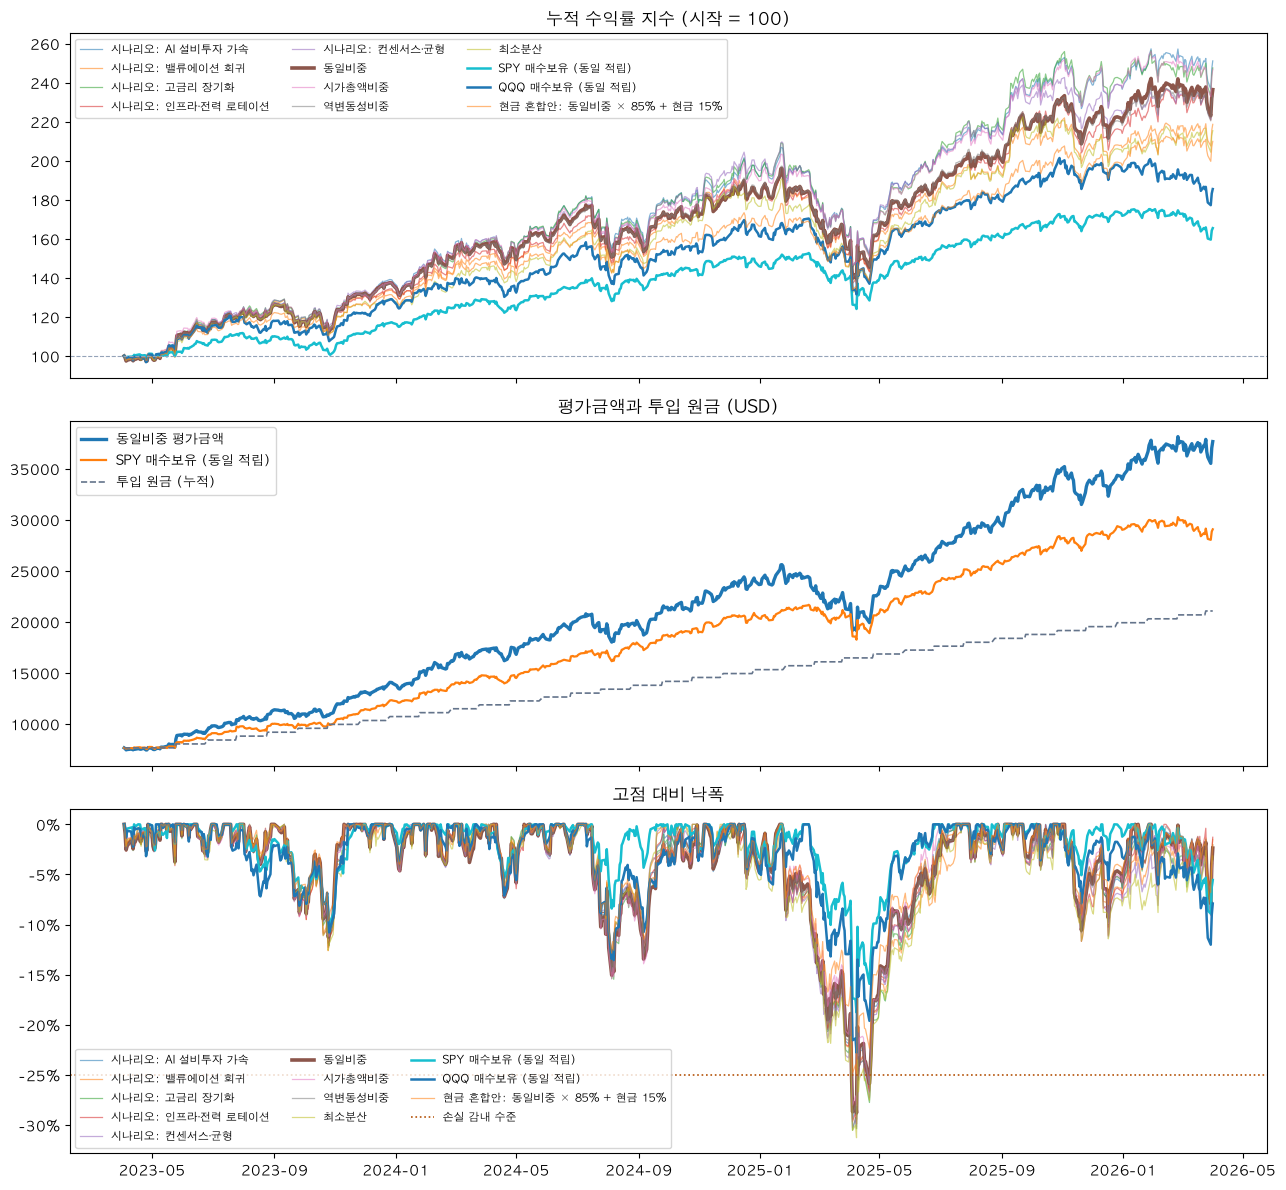

동일비중 최대낙폭 -28.8%: 고점 2025-01-23 → 저점 2025-04-08 → 회복 2025-07-17 (고점 아래 175일)


In [8]:
dates = pd.to_datetime(BT["series_dates"]); series = {p["id"]: p for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]}
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for pid, p in series.items():
    lw = 2.6 if pid == chosen else (1.8 if p["kind"] == "benchmark" else 0.9); alpha = 1 if (pid == chosen or p["kind"] == "benchmark") else 0.55
    axes[0].plot(dates, p["series"]["index"], lw=lw, alpha=alpha, label=label(p))
    axes[2].plot(dates, p["series"]["drawdown"], lw=lw, alpha=alpha, label=label(p))
axes[0].axhline(100, color="#94a3b8", ls="--", lw=0.8); axes[0].set_title("누적 수익률 지수 (시작 = 100)"); axes[0].legend(ncol=3, fontsize=8)
cp = series[chosen]; led = {l["date"]: l["amount_usd"] for l in cp["contribution_ledger"]}; inv, cum = [], cp["money"]["initial_usd"]
for ds in BT["series_dates"]: cum += led.get(ds, 0.0); inv.append(cum)
axes[1].plot(dates, cp["series"]["value_usd"], lw=2.4, label=f"{label(cp)} 평가금액"); axes[1].plot(dates, series[BT["benchmark"]["id"]]["series"]["value_usd"], lw=1.6, label="SPY 매수보유 (동일 적립)")
axes[1].plot(dates, inv, lw=1.2, ls="--", color="#64748b", label="투입 원금 (누적)"); axes[1].set_title("평가금액과 투입 원금 (USD)"); axes[1].legend(fontsize=9)
axes[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); axes[2].set_title("고점 대비 낙폭"); axes[2].axhline(-R["intent"]["risk_params"]["effective_max_drawdown"], color="#b45309", ls=":", lw=1.2, label="손실 감내 수준")
axes[2].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()
mdd = cp["metrics"]["risk"]["mdd"]; print(f"{label(cp)} 최대낙폭 {cp['headline']['max_drawdown']:.1%}: 고점 {mdd['peak_date']} → 저점 {mdd['trough_date']} → 회복 {mdd['recovery_date'] or '기간 내 미회복'} (고점 아래 {mdd['underwater_days']}일)")

,2023,2024,2025,2026
동일비중,+36.4%,+32.8%,+21.4%,+7.5%
SPY 매수보유 (동일 적립),+16.9%,+24.9%,+17.7%,-3.7%


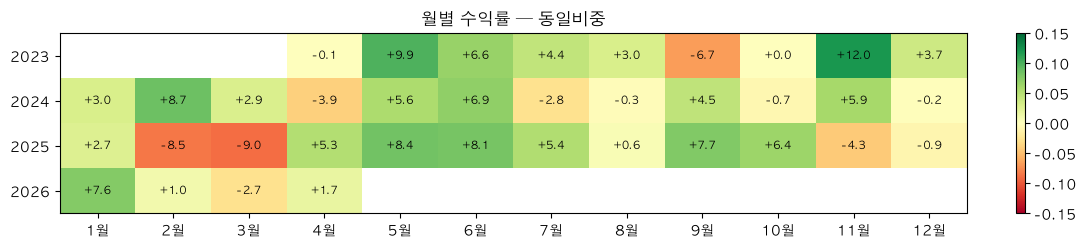

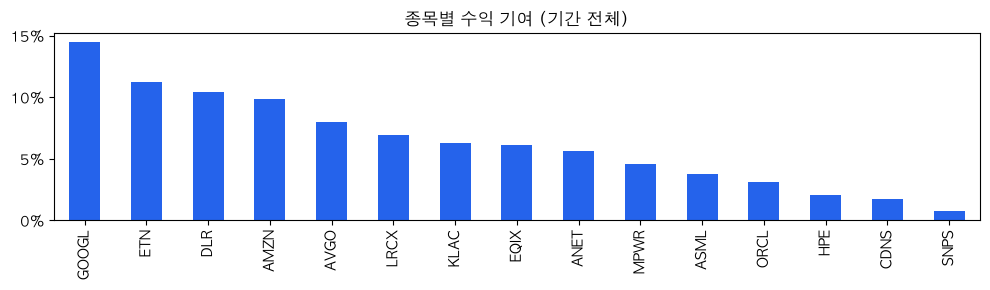

In [9]:
yr = pd.DataFrame({label(p): p["yearly_returns"] for p in [cp, series[BT["benchmark"]["id"]], series[P["targets"]["baseline"]["id"]]]}).T
display(yr.style.format("{:+.1%}", na_rep="–").set_caption("연도별 수익률 (첫해·마지막 해는 부분 기간)"))
mr = pd.DataFrame(cp["monthly_returns"]).pivot(index="year", columns="month", values="return")
fig, ax = plt.subplots(figsize=(11, 2.6)); im = ax.imshow(mr.values, cmap="RdYlGn", vmin=-0.15, vmax=0.15, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels([f"{m}월" for m in range(1, 13)]); ax.set_yticks(range(len(mr.index))); ax.set_yticklabels(mr.index)
for i in range(mr.shape[0]):
    for j in range(mr.shape[1]):
        v = mr.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v*100:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title(f"월별 수익률 — {label(cp)}"); plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()
contrib = pd.Series(cp["ticker_contribution"]).sort_values(ascending=False)
ax = contrib.plot.bar(figsize=(10, 3), color=["#2563eb" if v >= 0 else "#b45309" for v in contrib]); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.set_title("종목별 수익 기여 (기간 전체)"); plt.tight_layout(); plt.show()

### 리밸런싱 시점별 구성과 성과
각 리밸런싱일의 **조정 후 비중**(행)과 그 **직전 구간 성과**, 그 시점까지의 누적 지표입니다.

In [10]:
cps = cp["checkpoints"]
wt = pd.DataFrame({c["date"]: c["weights"]["after"] for c in cps}).T
display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption(f"리밸런싱 후 비중 — {label(cp)}"))
rows = []
for c in cps:
    sl, td = c["since_last"] or {}, c["to_date"] or {}
    rows.append({"날짜": c["date"], "구분": c["kind"], "평가금액": c["money"]["value_usd"], "투입 원금": c["money"]["net_invested_usd"], "구간 수익": sl.get("return"), "SPY 구간": sl.get("benchmark_return"),
                 "구간 최대낙폭": sl.get("max_drawdown"), "최고 종목": f"{sl['best']['ticker']} {sl['best']['return']:+.1%}" if sl else "", "최저 종목": f"{sl['worst']['ticker']} {sl['worst']['return']:+.1%}" if sl else "",
                 "누적 CAGR": td.get("cagr"), "누적 MDD": td.get("max_drawdown"), "누적 Sharpe": td.get("sharpe"), "거래": len(c["trades"]), "비용": c["commission_usd"]})
display(pd.DataFrame(rows).set_index("날짜").style.format({"평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "구간 수익": "{:+.1%}", "SPY 구간": "{:+.1%}", "구간 최대낙폭": "{:.1%}", "누적 CAGR": "{:+.1%}", "누적 MDD": "{:.1%}", "누적 Sharpe": "{:.2f}", "비용": "{:.2f}"}, na_rep="–"))

,ETN,CDNS,SNPS,ORCL,KLAC,MPWR,AVGO,EQIX,DLR,GOOGL,AMZN,ANET,ASML,HPE,LRCX
2023-04-03,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2023-07-03,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2023-10-02,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2024-01-02,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2024-04-01,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2024-07-01,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2024-10-01,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2025-01-02,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2025-04-01,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%
2025-07-01,12.0%,4.0%,4.0%,4.0%,4.0%,4.0%,4.0%,12.0%,12.0%,12.0%,12.0%,4.0%,4.0%,4.0%,4.0%


,구분,평가금액,투입 원금,구간 수익,SPY 구간,구간 최대낙폭,최고 종목,최저 종목,누적 CAGR,누적 MDD,누적 Sharpe,거래,비용
날짜,,,,,,,,,,,,,
2023-04-03,rebalance,"7,656","7,660",–,–,–,,,–,–,–,15,3.83
2023-07-03,rebalance,"9,821","8,426",+17.3%,+8.4%,-3.7%,AVGO +37.1%,ANET -4.7%,+91.1%,-3.7%,4.20,15,0.29
2023-10-02,rebalance,"10,982","9,575",+0.3%,-3.4%,-8.8%,ANET +17.5%,ASML -20.5%,+38.6%,-8.8%,1.82,15,0.36
2024-01-02,rebalance,"13,754","10,724",+14.2%,+11.1%,-8.5%,MPWR +31.7%,HPE -2.2%,+48.5%,-11.2%,2.32,15,0.35
2024-04-01,rebalance,"17,341","11,873",+17.3%,+10.8%,-4.0%,ASML +38.7%,EQIX -0.8%,+58.4%,-11.2%,2.80,15,0.68
2024-07-01,rebalance,"20,107","13,022",+8.9%,+4.8%,-7.2%,MPWR +22.8%,EQIX -4.5%,+54.6%,-11.2%,2.63,15,0.63
2024-10-01,rebalance,"21,168","14,171",-0.6%,+4.6%,-15.0%,ORCL +17.2%,LRCX -24.6%,+43.0%,-15.0%,1.85,15,1.05
2025-01-02,rebalance,"23,685","15,320",+6.4%,+3.2%,-5.0%,AVGO +38.9%,MPWR -33.2%,+40.6%,-15.0%,1.75,15,1.11
2025-04-01,rebalance,"21,445","16,469",-13.7%,-3.7%,-21.1%,KLAC +7.4%,ANET -29.8%,+25.3%,-21.1%,0.95,15,0.65


In [11]:
vd = [(label(p), v["type"], v["summary_ko"].split(" — ")[0], v["expected_return_annual"], v["realized"], "적중" if v["hit"] else "빗나감") for p in BT["portfolios"] for v in p["view_diagnostics"]]
if vd:
    display(pd.DataFrame(vd, columns=["시나리오", "유형", "뷰", "기대", "실제(12개월)", "방향"]).style.format({"기대": "{:+.0%}", "실제(12개월)": "{:+.1%}"}).set_caption("시나리오 뷰 사후 점검 (구성 후 12개월 실현 수익)"))

,시나리오,유형,뷰,기대,실제(12개월),방향
0,시나리오: AI 설비투자 가속,absolute,[절대] AVGO +30%/년 (신뢰 0.50),+30%,+112.5%,적중
1,시나리오: AI 설비투자 가속,absolute,[절대] KLAC +22%/년 (신뢰 0.40),+22%,+75.9%,빗나감
2,시나리오: AI 설비투자 가속,relative,[상대] CDNS+SNPS > ORCL +8%/년 (신뢰 0.40),+8%,+11.3%,적중
3,시나리오: AI 설비투자 가속,relative,[상대] AVGO+KLAC+MPWR > EQIX+DLR +12%/년 (신뢰 0.45),+12%,+38.9%,적중
4,시나리오: 밸류에이션 회귀,absolute,[절대] CDNS +5%/년 (신뢰 0.40),+5%,+44.9%,빗나감
5,시나리오: 밸류에이션 회귀,absolute,[절대] SNPS +5%/년 (신뢰 0.35),+5%,+46.5%,빗나감
6,시나리오: 밸류에이션 회귀,relative,[상대] GOOGL+AMZN > CDNS+SNPS +10%/년 (신뢰 0.40),+10%,+16.6%,적중
7,시나리오: 밸류에이션 회귀,relative,[상대] EQIX+DLR > MPWR +6%/년 (신뢰 0.30),+6%,+2.1%,적중
8,시나리오: 고금리 장기화,absolute,[절대] EQIX +2%/년 (신뢰 0.40),+2%,+13.9%,적중
9,시나리오: 고금리 장기화,absolute,[절대] DLR +0%/년 (신뢰 0.40),+0%,+55.7%,빗나감


## 6. 검증 — 사용자 기준(손실 감내 수준·목표 수익·제약)에 비춰 본 판정

In [12]:
V = R["validation"]; print("기준:", {k: V["criteria"][k] for k in ["max_drawdown", "target_annual_return", "benchmark", "volatility_preference", "max_weight_per_stock", "max_weight_per_sector", "min_holdings"]})
mat = pd.DataFrame({label(series[r["id"]]): {c["rule"] + " " + c["name_ko"]: c["status"] for c in r["checks"]} for r in V["results"]}).T
color = lambda s: "background-color:#dcfce7" if s == "pass" else ("background-color:#fef3c7" if s == "warn" else "background-color:#fee2e2")
display(mat.style.map(color).set_caption("규칙별 판정 (pass 통과 / warn 주의 / fail 미통과)"))
print("요약:", V["summary"]); print("추천:", V["recommended"]["id"] + " — " + V["recommended"]["reason_ko"] if V["recommended"] else "추천 없음 — " + "; ".join(V["warnings"]))
for alt in V.get("alternatives", []): print(f"대안 {alt['name_ko']}: {alt['reason_ko']} 판정 {alt['status']}")
inf = V["criteria"].get("selection_infeasibility")
if inf: print(f"종목 수 미달 사유: 섹터 상한 {inf['sector_cap']:.0%} 로 최대 {inf['max_feasible_n']}종목 (목표 {inf['target']}); 선택지: " + " / ".join(inf["options_ko"]))
chk = pd.DataFrame(next(r for r in V["results"] if r["id"] == chosen)["checks"])[["rule", "name_ko", "level", "status", "message_ko"]]
display(chk.set_index("rule").rename(columns={"name_ko": "항목", "level": "수준", "status": "판정", "message_ko": "측정 결과"}).style.set_caption(f"{label(cp)} 상세"))

기준: {'max_drawdown': 0.25, 'target_annual_return': 0.12, 'benchmark': 'SPY', 'volatility_preference': 'medium', 'max_weight_per_stock': 0.15, 'max_weight_per_sector': 0.4, 'min_holdings': 10}


,R1 최대낙폭,R2 목표수익,R3 비교지수 대비,R4 종목 상한(리밸런싱일),R4b 종목 상한(드리프트),R5 섹터 상한(리밸런싱일),R5b 섹터 상한(드리프트),R6 종목 수,R7 변동성 적합,R8 데이터 무결성
시나리오: AI 설비투자 가속,fail,pass,pass,pass,pass,pass,pass,pass,pass,pass
시나리오: 밸류에이션 회귀,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass
시나리오: 고금리 장기화,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass
시나리오: 인프라·전력 로테이션,fail,pass,pass,pass,pass,pass,pass,pass,pass,pass
시나리오: 컨센서스·균형,fail,pass,pass,pass,pass,pass,pass,pass,pass,pass
동일비중,fail,pass,pass,pass,pass,pass,pass,pass,pass,pass
시가총액비중,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass
역변동성비중,fail,pass,pass,pass,pass,pass,pass,pass,pass,pass
최소분산,fail,pass,pass,pass,warn,pass,pass,pass,pass,pass


요약: {'n_pass': 0, 'n_warn': 0, 'n_fail': 9}
추천: 추천 없음 — no portfolio passed the hard rules (fail counts by rule: {'R1': 9}); recommended=null
대안 현금 혼합안: 동일비중 × 85% + 현금 15%: 동일비중의 과거 최대낙폭이 허용 25%를 넘어, 같은 종목 비중을 85%로 줄이고 15%를 현금(수익 0 가정)으로 두었을 때의 결과입니다. 실제 백테스트 최대낙폭 -24.9%, CAGR 28.2%. 판정 pass


,항목,수준,판정,측정 결과
rule,,,,
R1,최대낙폭,hard,fail,최대낙폭 28.8% > 허용 25%
R2,목표수익,soft,pass,CAGR 33.5% vs 목표 12%
R3,비교지수 대비,soft,pass,SPY 대비 초과 CAGR +15.1%
R4,종목 상한(리밸런싱일),hard,pass,리밸런싱일 최대 종목 비중 12.0% vs 상한 15%
R4b,종목 상한(드리프트),soft,pass,리밸런싱 사이 종목 비중 드리프트 허용 범위 안
R5,섹터 상한(리밸런싱일),hard,pass,리밸런싱일 최대 섹터 비중 40.0% vs 상한 40%
R5b,섹터 상한(드리프트),soft,pass,리밸런싱 사이 섹터 드리프트 허용 범위 안
R6,종목 수,hard,pass,보유 종목 15개 vs 최소 10개
R7,변동성 적합,soft,pass,연변동성 23.8% vs 성향(medium) 상한 30%


## 7. 비용·조건·경고

In [13]:
u = R["llm_usage"]
if u.get("available"):
    display(pd.DataFrame(u["by_stage"]).T.style.format({"cost_usd": "{:.4f}"}).set_caption(f"분석 모델 호출 (누적, {u['model']}) — 합계 {u['total_cost_usd']:.4f} USD"))
display(pd.DataFrame(R["sources"])[["name", "what"]].rename(columns={"name": "출처", "what": "사용한 내용"}).set_index("출처"))
print("파라미터:", json.dumps(R["parameters"], ensure_ascii=False)[:600])
pd.DataFrame(R["warnings"]).rename(columns={"stage": "단계", "message": "경고"})

,calls,prompt_tokens,completion_tokens,cost_usd
02_intent,1.000000,6488.000000,1980.000000,0.0024
04_classify,2.000000,3094.000000,7314.000000,0.0044
06_explain,1.000000,950.000000,1814.000000,0.0010
00_descriptor,1.000000,3858.000000,3966.000000,0.0029
09_views,1.000000,1883.000000,3242.000000,0.0020
14a_interpret,2.000000,13270.000000,5743.000000,0.0059
14b_narrate,2.000000,26033.000000,9048.000000,0.0104


,사용한 내용
출처,
Yahoo Finance (yfinance),"일별 주가·수정주가·거래량 (2011-10 ~ 2026-10), 벤치마크 SPY"
Yahoo Finance (yfinance) 기업 개요,"회사 한 줄 소개(영문 사업 설명 첫 문장), 발행주식수, 재무제표 스냅샷"
Wikipedia,S&P 500 · NASDAQ-100 구성 종목과 GICS 세부산업
Wikipedia GICS,GICS 11 섹터 / 25 산업그룹 / 74 산업 / 163 세부산업 분류표
Yahoo Finance KRW=X,원/달러 환율 (투자금 환산 기준일 종가)
MyFinSight 파이프라인 계산,후보 검색·정량 스크린·비중 계산·Black-Litterman·백테스트(bt)·검증 규칙
분석 모델 (gpt-6-luna),"의도 해석, 테마 분류, 시나리오 뷰(뉴스 미연결 가정), 리포트 서술"


파라미터: {"portfolio": {"LOOKBACK_DAYS": 756, "SHRINKAGE": "ledoit_wolf", "TAU": 0.05, "RISK_AVERSION": {"conservative": 4.0, "moderate": 2.5, "aggressive": 1.5}, "OMEGA_METHOD": "he_litterman_confidence", "CONFIDENCE_FLOOR": 0.1, "ABS_RETURN_RANGE": [-0.5, 1.0], "REL_RETURN_RANGE": [0.0, 0.5], "TEMPLATES": ["equal_weight", "market_cap", "inverse_volatility", "min_variance"]}, "backtest": {"COMMISSION_BPS": 5, "INTEGER_POSITIONS": false, "RISK_FREE_RATE": 0.04, "TRADING_DAYS": 252, "DRIFT_TOLERANCE": 0.25, "CHECKPOINT_FREQ": "rebalance", "VOL_BANDS": {"low": 0.15, "medium": 0.3, "high": 9.99}}, "llm": 


,단계,경고
0,02,theme ai_semiconductor: dropped tickers outside universe ['TSM']
1,05,"sector name preference (6/sector) exceeded for 2 tickers ['NBIS', 'TER']; se..."
2,07,stage5@2023-04-03: sector name preference (6/sector) exceeded for 4 tickers ...
3,07,"capital re-converted at 2023-04-03 FX 1305.48: 7,660 USD vs request-date 6,6..."
4,12,no portfolio passed the hard rules (fail counts by rule: {'R1': 9}); recomme...
